In [267]:
import os

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.colors as mcl

from files import data

In [22]:
# Make sure this matches project root every time

ROOT = 'SSU-Data-Dash-2026-Toronto-Home-Price-Prediction-Challenge'

if os.path.basename(os.getcwd()) != ROOT:
    os.chdir(ROOT)

os.environ["DATA_DIR"] = "datasets"

In [27]:
listings = data.load("listings")

off_market = data.load("off_market")
list_aware = data.load("list_aware")

In [48]:
', '.join(listings.columns)

'ml_num, sold_price, list_price, date_listed, date_sold, days_on_market, house_type_name, house_style, bedrooms, washrooms, parking_total, garage, house_area, lot_front, lot_depth, municipality, community, latitude, longitude, external_avm_estimate, external_avm_estimate_date, remarks'

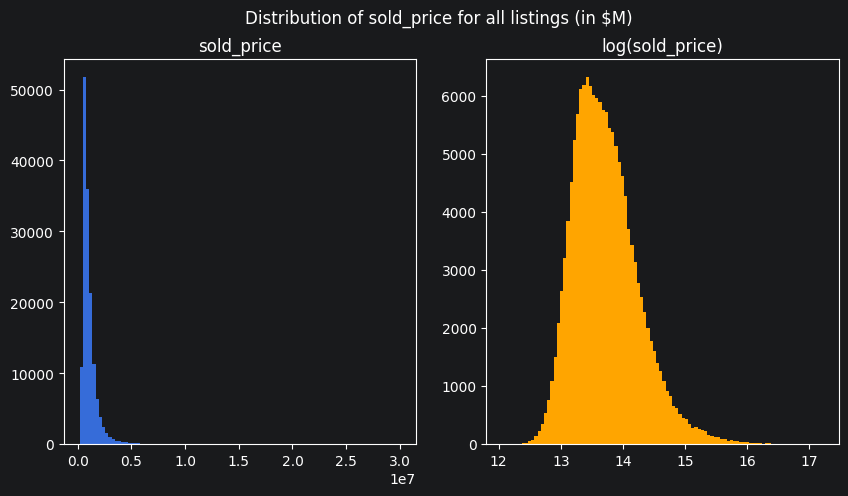

In [284]:
fig, axes = plt.subplots(1, 2, figsize = (10, 5))

axes[0].hist(listings['sold_price'], bins = 100)
axes[0].set(title = 'sold_price')

axes[1].hist(np.log(listings['sold_price']), bins = 100, color = 'orange')
axes[1].set(title = 'log(sold_price)')

plt.suptitle('Distribution of sold_price for all listings (in $M)')
plt.show()

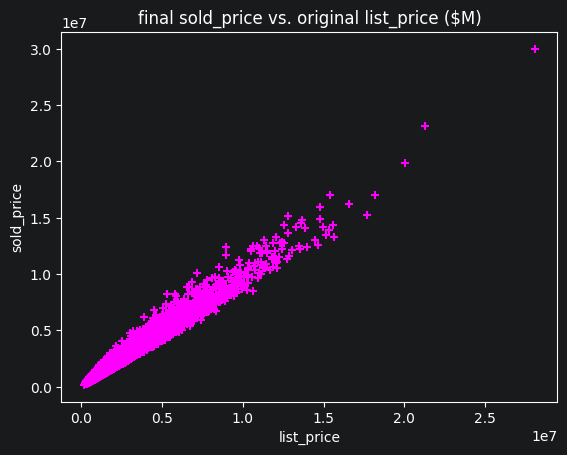

In [68]:
plt.scatter('list_price', 'sold_price', data = listings, marker = '+', color = 'magenta')

plt.title('final sold_price vs. original list_price (in $M)')

plt.xlabel('list_price')
plt.ylabel('sold_price')

plt.show()

In [134]:
avm_est_available = listings[listings['external_avm_estimate_date'] < listings['date_sold']]

print(f'{len(avm_est_available)} records with external_avm_estimate available before date_sold')
print(f'({np.round(len(avm_est_available) / len(listings) * 100, 2)}% of complete dataset)')

44716 records with external_avm_estimate available before date_sold
(29.81% of complete dataset)


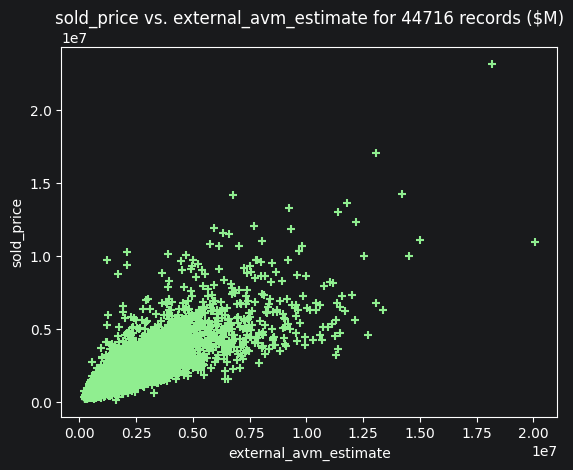

In [136]:
plt.scatter('external_avm_estimate', 'sold_price', data = avm_est_available, marker = '+', color = 'lightgreen')

plt.title(f'sold_price vs. external_avm_estimate for {len(avm_est_available)} records (in $M)')

plt.xlabel('external_avm_estimate')
plt.ylabel('sold_price')

plt.show()

In [187]:
listings[['house_type_name', 'sold_price']].groupby('house_type_name').describe().round(2)

sold_price                                               \
                        count        mean         std       min        25%   
house_type_name                                                              
Co-Op Apt               729.0   755315.64   556019.33  262700.0   519400.0   
Condo Apt             76374.0   699026.08   277399.40  172600.0   530500.0   
Condo Townhouse       10160.0   842632.68   273856.26  336700.0   656875.0   
Detached              43202.0  1688777.61  1153124.38  205900.0  1054100.0   
Freehold Townhouse     5138.0  1283139.04   506767.35  558800.0   957725.0   
Semi-Detached         14397.0  1322291.15   565621.88  454600.0   981700.0   

                                                      
                          50%        75%         max  
house_type_name                                       
Co-Op Apt            646600.0   838200.0   9703100.0  
Condo Apt            644300.0   799100.0  10300300.0  
Condo Townhouse      786200.0   962000.0   3406000.0  
Detached            1367850.0  1895175.0  30000000.0  
Freehold Townhouse  1146600.0  1451125.0   8827900.0  
Semi-Detached       1179100.0  1485600.0  11839300.0

In [188]:
listings[['municipality', 'sold_price']].groupby('municipality').describe().round(2)

sold_price                                                       \
                  count        mean        std       min       25%       50%   
municipality                                                                   
Etobicoke       14315.0   931949.44  585444.51  206400.0  552400.0  742600.0   
North York      27555.0  1038978.84  782344.91  221600.0  619600.0  835800.0   
Scarborough     21078.0  1028169.12  790277.90  205900.0  593900.0  814100.0   
Toronto         85323.0  1124122.95  860821.73  172600.0  649200.0  894600.0   
York             1729.0   886261.42  363870.70  292900.0  621300.0  786200.0   

                                     
                    75%         max  
municipality                         
Etobicoke     1107600.0   9946400.0  
North York    1190400.0  30000000.0  
Scarborough   1204400.0  23145600.0  
Toronto       1288500.0  17035700.0  
York          1066000.0   3976300.0

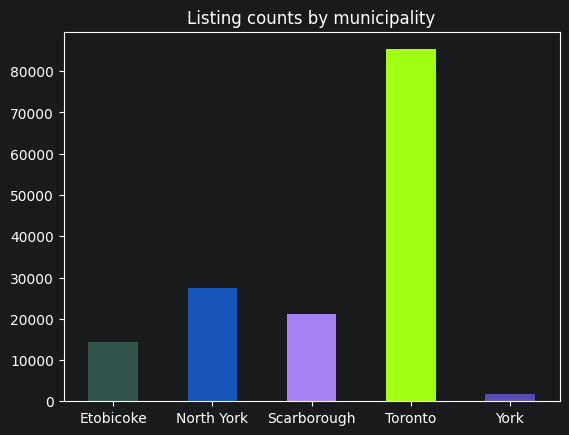

municipality
Toronto        85323
North York     27555
Scarborough    21078
Etobicoke      14315
York            1729
Name: count, dtype: int64


In [269]:
np.random.seed(91)

muni_counts = listings['municipality'].value_counts()

muni_colors = [mcl.to_hex(color) for color in np.random.rand(len(muni_counts), 3)]

muni_counts.sort_index().plot(kind = 'bar', rot = 0, color = muni_colors)

plt.title('Listing counts by municipality')
plt.xlabel(None)

plt.show()

print(muni_counts)

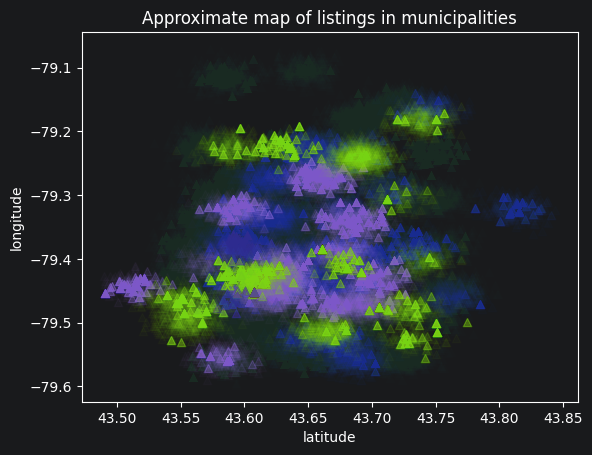

In [273]:
for i, muni in enumerate(muni_counts.index):
    plt.scatter('latitude', 'longitude', data = listings[listings['municipality'] == muni],
                marker = '^', color = muni_colors[i], alpha = 0.025)

plt.title(f'Approximate map of listings in municipalities')

plt.xlabel('latitude')
plt.ylabel('longitude')

plt.show()

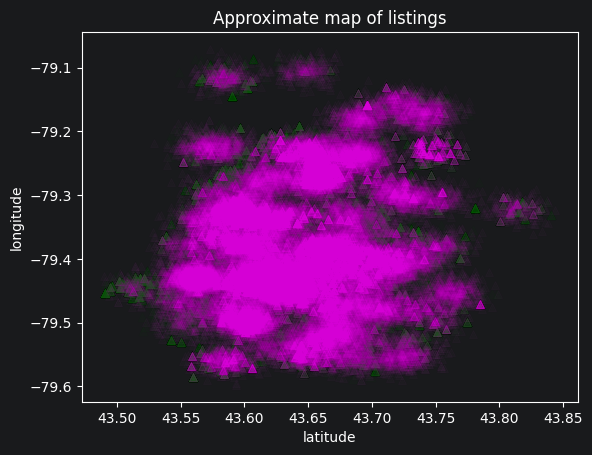

In [259]:
plt.scatter('latitude', 'longitude', data = listings, marker = '^', color = 'green', alpha = 0.025)

plt.scatter('latitude', 'longitude', data = listings[listings['sold_price'] > listings['sold_price'].median()],
            marker = '^', color = 'magenta', alpha = 0.025)

plt.title(f'Approximate map of listings')

plt.xlabel('latitude')
plt.ylabel('longitude')

plt.show()

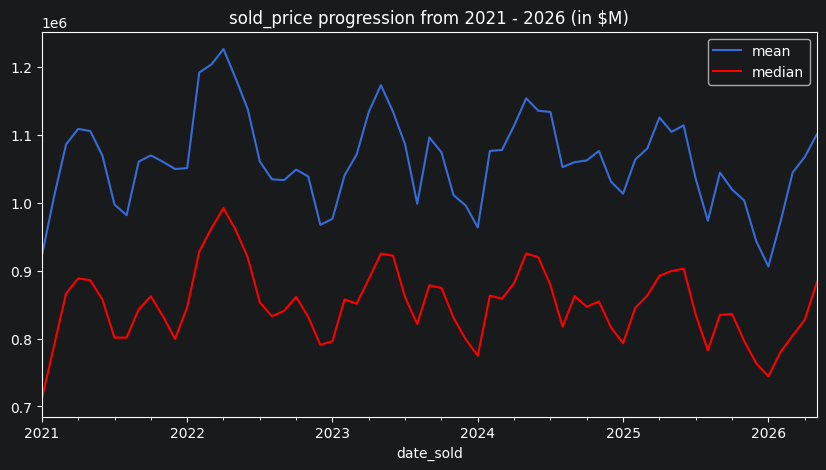

In [306]:
monthly_means = listings[['date_sold', 'sold_price']].groupby(listings['date_sold'].dt.to_period('M'))['sold_price'].mean()
monthly_medis = listings[['date_sold', 'sold_price']].groupby(listings['date_sold'].dt.to_period('M'))['sold_price'].median()

monthly_means.plot(figsize = (10, 5), kind = 'line', label = 'mean')
monthly_medis.plot(figsize = (10, 5), kind = 'line', label = 'median', color = 'red')

plt.title("sold_price progression from 2021 - 2026 (in $M)")

plt.legend()

plt.show()

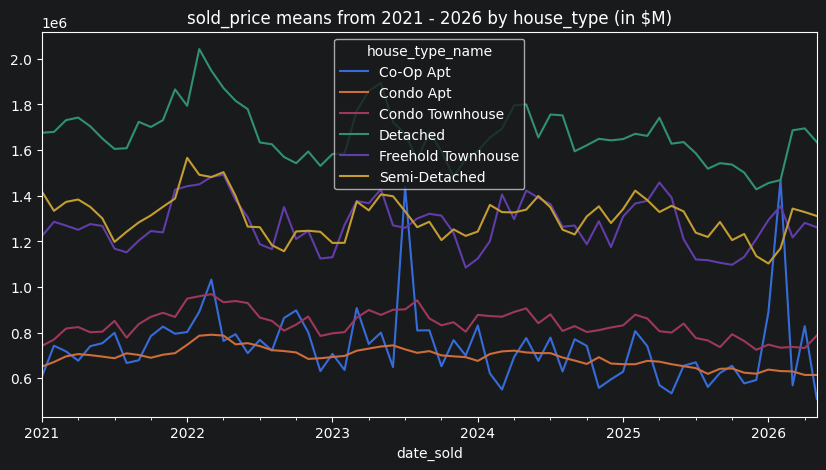

In [310]:
monthly_ht_means = listings[['date_sold', 'house_type_name', 'sold_price']].groupby(
    [listings['date_sold'].dt.to_period('M'), 'house_type_name'])['sold_price'].mean()

monthly_ht_means.unstack().plot(figsize = (10, 5))

plt.title("sold_price means from 2021 - 2026 by house_type (in $M)")

plt.show()

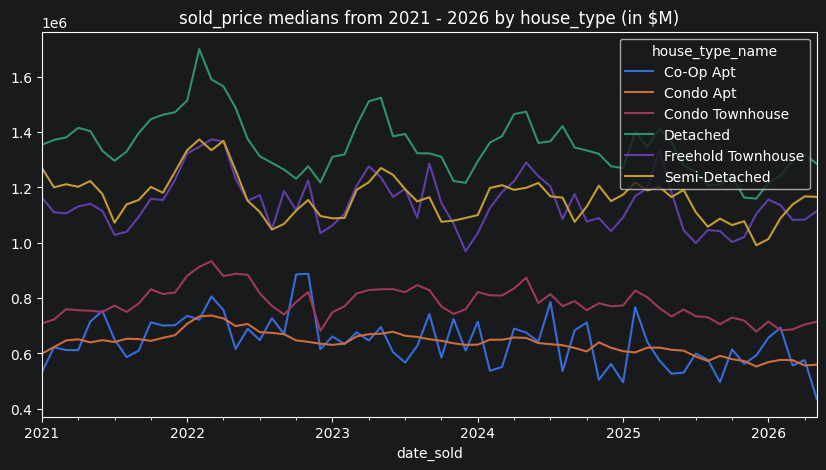

In [311]:
monthly_ht_medis = listings[['date_sold', 'house_type_name', 'sold_price']].groupby(
    [listings['date_sold'].dt.to_period('M'), 'house_type_name'])['sold_price'].median()

monthly_ht_medis.unstack().plot(figsize = (10, 5))

plt.title("sold_price medians from 2021 - 2026 by house_type (in $M)")

plt.show()

In [111]:
(listings['date_sold'] - listings['date_listed']).dt.days == listings['days_on_market']

0         True
1         True
2         True
3         True
4         True
          ... 
149995    True
149996    True
149997    True
149998    True
149999    True
Length: 150000, dtype: bool

In [98]:
listings['remarks'].apply(lambda row: len(row.split()))

0         49
1         86
2         41
3         55
4         67
          ..
149995    69
149996    48
149997    69
149998    69
149999    60
Name: remarks, Length: 150000, dtype: int64

In [154]:
def find_word_in_remarks(df, word):
    return df[df['remarks'].apply(lambda row: word.lower() in row.lower())]

In [156]:
find_word_in_remarks(listings, 'spacious').head(3)

,ml_num,sold_price,list_price,date_listed,date_sold,days_on_market,house_type_name,house_style,bedrooms,washrooms,...,house_area,lot_front,lot_depth,municipality,community,latitude,longitude,external_avm_estimate,external_avm_estimate_date,remarks
15,SYN-0142927,2306300.0,2125500.0,2020-12-31,2021-01-01,1,Detached,2-Storey,5,5,...,2800-2999,18.86,185.71,Toronto,Magnoliaglen,43.694779,-79.486089,2302600.0,2021-08-10,Could this 5-bedroom home in Magnoliaglen be y...
22,SYN-0006539,546800.0,632400.0,2020-12-06,2021-01-01,26,Condo Apt,Apartment,2,2,...,1000-1199,NaN,NaN,North York,Pinevale,43.719760,-79.306719,538700.0,2021-09-17,Visualize the possibilities in this spacious t...
23,SYN-0064704,550400.0,597800.0,2020-12-31,2021-01-01,1,Condo Apt,Apartment,1,1,...,658,NaN,NaN,Scarborough,Rowangardens,43.706726,-79.420079,585200.0,2021-04-21,This cozy apartment on Alder Gardens is a perf...


In [202]:
listings['list_price'].cov(listings['sold_price']) / (listings['list_price'].std() * listings['sold_price'].std())

np.float64(0.985755204783829)

In [205]:
homes_sort = listings.sort_values(by = 'date_sold', ascending = True).reset_index(drop = True)

In [230]:
train_prop = 0.8

n = int(len(homes_sort) * 0.8)
v = len(homes_sort) - n

In [238]:
X_train = np.concat([np.ones((n, 1)), np.log(np.array(homes_sort[:n]['list_price']).reshape((n, 1)))], axis = 1)

In [239]:
y_train = np.log(np.array(homes_sort[:n]['sold_price']).reshape((n, 1)))

In [241]:
B = np.linalg.inv(X_train.T @ X_train) @ X_train.T @ y_train

In [274]:
X_valid = np.concat([np.ones((v, 1)), np.log(np.array(homes_sort[n:]['list_price']).reshape((v, 1)))], axis = 1)

In [277]:
y_valid = np.log(np.array(homes_sort[n:]['sold_price']).reshape((v, 1)))

In [278]:
((y_valid - X_valid @ B) ** 2).sum() / v

np.float64(0.00971380921909101)